<a href="https://colab.research.google.com/github/mercygerman/KNOWLEGE-CHECK-FOR-MODULE-1/blob/main/Another_copy_of_Workshop_Activity_Multi_Asset_Integrity_Dashboard_Group_A_Work.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Subsea Asset Integrity Dashboard
Synthetic SCADA, Design Envelope, Corrosion, Fatigue and Automated Alerts
Purpose: Demonstrate an engineering-physics-informed integrity dashboard for eight synthetic subsea assets over 12 months of hourly data.

Synthetic data volume: 8 assets × 8,760 hourly timestamps = 70,080 records.

Engineering disclaimer: All asset names, operating limits, corrosion rates, wall thicknesses, hydrate/WAT boundaries, and fatigue S–N parameters are illustrative. This is a learning prototype, not an integrity assessment tool or a substitute for approved design documentation, DNV/API procedures, qualified engineering review, or validated field data.

What this notebook includes
Synthetic hourly SCADA data for eight assets.
A pressure–temperature (P–T) envelope with the latest operating point.
Corrosion rate trends and remaining-life estimates.
Fatigue damage accumulation using Miner’s rule and an illustrative S–N relationship.
Automated alerts for envelope exceedances, corrosion, wall thickness, and fatigue damage.
A fleet summary and asset selector.

Import libraries and configure the simulation
Run this cell first.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from dataclasses import dataclass
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

START_DATE = "2025-01-01 00:00:00"
PERIODS = 365 * 24  # 8,760 hourly records per asset
TIMESTAMPS = pd.date_range(START_DATE, periods=PERIODS, freq="h")

print(f"Simulation timestamps: {len(TIMESTAMPS):,}")
print(f"Fleet size: 8 assets")
print(f"Expected SCADA rows: {len(TIMESTAMPS) * 8:,}")

Simulation timestamps: 8,760
Fleet size: 8 assets
Expected SCADA rows: 70,080


2. Define asset configuration and engineering functions
The SubseaAsset class stores the illustrative design and integrity parameters for each asset. Functions calculate the design pressure limit, corrosion remaining life, S–N fatigue life, and accumulated Miner damage.

Physics used

Pressure limit: a simplified temperature-dependent pressure limit, capped by the asset’s MAOP.
Corrosion remaining life: (current wall thickness − minimum allowable thickness) / corrosion rate.
Fatigue: N = 10^(logA − m log10(Δσ)); Miner’s rule is D = Σ(nᵢ/Nᵢ).
Envelope check: pressure must remain below the pressure limit, while temperature must be above both the illustrative hydrate boundary and wax appearance temperature (WAT).
These simplified equations are intended to demonstrate software architecture and monitoring logic. Replace them with approved asset-specific engineering models before operational use.

In [ ]:
@dataclass
class SubseaAsset:
    asset_id: str
    asset_type: str
    maop_bar: float
    design_temp_min_c: float
    design_temp_max_c: float
    initial_wall_mm: float
    minimum_wall_mm: float
    nominal_corrosion_mm_y: float
    wat_c: float
    log_a: float = 12.164
    sn_slope_m: float = 3.0

    def pressure_limit_bar(self, temperature_c):
        """Illustrative temperature-dependent pressure limit, capped at MAOP."""
        temperature_c = np.asarray(temperature_c)
        temp_factor = 1.0 - 0.0015 * np.maximum(temperature_c - 20.0, 0.0)
        return np.minimum(self.maop_bar, self.maop_bar * temp_factor)

    def hydrate_boundary_temp_c(self, pressure_bar):
        """Illustrative hydrate boundary: replace with a validated fluid model."""
        pressure_bar = np.asarray(pressure_bar)
        return 4.0 + 0.12 * pressure_bar

    def fatigue_cycles_to_failure(self, stress_range_mpa):
        """Illustrative S-N relation: log10(N) = logA - m*log10(stress range)."""
        stress = np.maximum(np.asarray(stress_range_mpa, dtype=float), 1e-6)
        return 10 ** (self.log_a - self.sn_slope_m * np.log10(stress))

    def remaining_life_years(self, current_wall_mm, corrosion_rate_mm_y):
        rate = np.asarray(corrosion_rate_mm_y, dtype=float)
        wall_margin = np.asarray(current_wall_mm, dtype=float) - self.minimum_wall_mm
        with np.errstate(divide="ignore", invalid="ignore"):
            life = np.where(rate > 0, wall_margin / rate, np.inf)
        return np.maximum(life, 0.0)


assets = [
    SubseaAsset("JMP-001", "Production Jumper", 120, -5, 80, 25.0, 20.0, 0.12, 18.0),
    SubseaAsset("JMP-002", "Production Jumper", 115, -5, 80, 24.0, 19.0, 0.15, 19.0),
    SubseaAsset("RIS-001", "Production Riser", 140, -5, 80, 32.0, 26.0, 0.10, 20.0),
    SubseaAsset("RIS-002", "Production Riser", 135, -5, 80, 30.0, 25.0, 0.14, 21.0),
    SubseaAsset("FLW-001", "Flowline", 100, -5, 80, 20.0, 16.0, 0.18, 17.0),
    SubseaAsset("FLW-002", "Flowline", 105, -5, 80, 22.0, 17.5, 0.13, 18.5),
    SubseaAsset("PLET-001", "PLET", 125, -5, 80, 28.0, 23.0, 0.08, 19.5),
    SubseaAsset("PLET-002", "PLET", 110, -5, 80, 26.0, 21.0, 0.16, 20.0),
]
asset_by_id = {asset.asset_id: asset for asset in assets}

print("Configured assets:", ", ".join(asset_by_id))

Configured assets: JMP-001, JMP-002, RIS-001, RIS-002, FLW-001, FLW-002, PLET-001, PLET-002


3. Generate 12 months of hourly synthetic SCADA data
The dataset includes pressure, temperature, flow, wall thickness, corrosion rate, stress range, and cumulative fatigue damage. A few injected operating excursions make it possible to test the alert system.

The data is synthetic, not measured from a real subsea field.

In [ ]:
def generate_asset_scada(asset: SubseaAsset, timestamps: pd.DatetimeIndex, rng):
    n = len(timestamps)
    t = np.arange(n)
    day_cycle = np.sin(2 * np.pi * t / 24)
    annual_cycle = np.sin(2 * np.pi * t / n)

    # Simulated operating conditions with noise and mild cycles.
    pressure = (
        0.72 * asset.maop_bar
        + 2.8 * day_cycle
        + 2.0 * annual_cycle
        + rng.normal(0, 2.2, n)
    )
    temperature = (
        27.0
        + 4.0 * np.sin(2 * np.pi * t / (24 * 14))
        + 1.8 * annual_cycle
        + rng.normal(0, 1.2, n)
    )
    flow_rate = 800 + 55 * np.sin(2 * np.pi * t / (24 * 7)) + rng.normal(0, 20, n)
    flow_rate = np.clip(flow_rate, 0, None)

    # Simulate corrosion rate variation and cumulative wall loss.
    corrosion_rate = asset.nominal_corrosion_mm_y * (
        1 + 0.12 * np.sin(2 * np.pi * t / (24 * 30)) + rng.normal(0, 0.025, n)
    )
    corrosion_rate = np.clip(corrosion_rate, asset.nominal_corrosion_mm_y * 0.5, None)
    elapsed_years = t / (365.0 * 24.0)
    wall_thickness = asset.initial_wall_mm - np.cumsum(corrosion_rate) / (365.0 * 24.0)

    # Hourly stress-range proxy; each hour is treated as one equivalent cycle for this demo.
    stress_range = 32 + 7 * np.abs(np.sin(2 * np.pi * t / (24 * 5))) + rng.normal(0, 4, n)
    stress_range = np.clip(stress_range, 10, None)

    # Inject short pressure and temperature excursions into selected assets.
    if asset.asset_id in {"JMP-002", "FLW-001", "PLET-002"}:
        for start in [1200, 4100, 6900]:
            if start + 5 < n:
                pressure[start:start + 5] = asset.maop_bar * rng.uniform(1.01, 1.06)
    if asset.asset_id in {"JMP-001", "RIS-002", "FLW-001"}:
        for start in [2100, 5300]:
            if start + 4 < n:
                temperature[start:start + 4] = rng.uniform(3.0, 7.0)

    cycles_to_failure = asset.fatigue_cycles_to_failure(stress_range)
    hourly_damage = 1.0 / cycles_to_failure
    cumulative_fatigue_damage = np.cumsum(hourly_damage)

    return pd.DataFrame({
        "timestamp": timestamps,
        "asset_id": asset.asset_id,
        "asset_type": asset.asset_type,
        "pressure_bar": pressure,
        "temperature_c": temperature,
        "flow_rate_m3_h": flow_rate,
        "wall_thickness_mm": wall_thickness,
        "corrosion_rate_mm_y": corrosion_rate,
        "stress_range_mpa": stress_range,
        "cycles_to_failure": cycles_to_failure,
        "hourly_fatigue_damage": hourly_damage,
        "cumulative_fatigue_damage": cumulative_fatigue_damage,
    })


scada = pd.concat(
    [generate_asset_scada(asset, TIMESTAMPS, rng) for asset in assets],
    ignore_index=True
)

scada["timestamp"] = pd.to_datetime(scada["timestamp"])
scada = scada.sort_values(["asset_id", "timestamp"]).reset_index(drop=True)

print("Dataset shape:", scada.shape)
display(scada.head())
display(scada.groupby("asset_id").agg(
    records=("timestamp", "count"),
    first_timestamp=("timestamp", "min"),
    last_timestamp=("timestamp", "max"),
    min_wall_mm=("wall_thickness_mm", "min"),
    max_pressure_bar=("pressure_bar", "max")
))

Dataset shape: (70080, 12)


,timestamp,asset_id,asset_type,pressure_bar,temperature_c,flow_rate_m3_h,wall_thickness_mm,corrosion_rate_mm_y,stress_range_mpa,cycles_to_failure,hourly_fatigue_damage,cumulative_fatigue_damage
0,2025-01-01 00:00:00,FLW-001,Flowline,73.938951,25.557277,796.283446,19.999979,0.179626,33.365651,3.927364e+07,2.546237e-08,2.546237e-08
1,2025-01-01 01:00:00,FLW-001,Flowline,71.313230,25.608644,806.926255,19.999959,0.181349,36.094265,3.102311e+07,3.223403e-08,5.769640e-08
2,2025-01-01 02:00:00,FLW-001,Flowline,72.252269,28.286458,788.096571,19.999938,0.181882,33.649873,3.828686e+07,2.611862e-08,8.381502e-08
3,2025-01-01 03:00:00,FLW-001,Flowline,75.582935,26.151040,829.536773,19.999918,0.177625,27.715917,6.851920e+07,1.459445e-08,9.840947e-08
4,2025-01-01 04:00:00,FLW-001,Flowline,73.430947,29.459741,800.949956,19.999897,0.182052,34.783606,3.466380e+07,2.884854e-08,1.272580e-07


,records,first_timestamp,last_timestamp,min_wall_mm,max_pressure_bar
asset_id,,,,,
FLW-001,8760,2025-01-01,2025-12-31 23:00:00,19.819879,105.097178
FLW-002,8760,2025-01-01,2025-12-31 23:00:00,21.869862,86.799876
JMP-001,8760,2025-01-01,2025-12-31 23:00:00,24.879896,97.607037
JMP-002,8760,2025-01-01,2025-12-31 23:00:00,23.849942,119.589643
PLET-001,8760,2025-01-01,2025-12-31 23:00:00,27.919955,100.258062
PLET-002,8760,2025-01-01,2025-12-31 23:00:00,25.839781,116.407356
RIS-001,8760,2025-01-01,2025-12-31 23:00:00,31.899914,112.814682
RIS-002,8760,2025-01-01,2025-12-31 23:00:00,29.859834,108.209196


4. Calculate envelope status, remaining life, and alerts
The envelope rule flags a record if pressure exceeds the temperature-adjusted pressure limit, temperature is below the illustrative hydrate boundary, or temperature is below WAT. Corrosion and fatigue warnings use configurable demonstration thresholds.

Important: A real operating envelope may involve more complex phase behavior, fluid composition, transient conditions, thermal hydraulics, and asset-specific limits. The simple hydrate/WAT checks here are illustrative monitoring logic.

In [ ]:
def add_integrity_indicators(data: pd.DataFrame, assets_by_id: dict) -> pd.DataFrame:
    frames = []
    for asset_id, group in data.groupby("asset_id", sort=False):
        asset = assets_by_id[asset_id]
        g = group.copy()

        g["pressure_limit_bar"] = asset.pressure_limit_bar(g["temperature_c"].to_numpy())
        g["hydrate_boundary_temp_c"] = asset.hydrate_boundary_temp_c(g["pressure_bar"].to_numpy())

        g["pressure_exceedance"] = g["pressure_bar"] > g["pressure_limit_bar"]
        g["hydrate_risk"] = g["temperature_c"] < g["hydrate_boundary_temp_c"]
        g["wat_risk"] = g["temperature_c"] < asset.wat_c
        g["envelope_exceedance"] = g["pressure_exceedance"] | g["hydrate_risk"] | g["wat_risk"]

        g["remaining_wall_margin_mm"] = g["wall_thickness_mm"] - asset.minimum_wall_mm
        g["remaining_life_years"] = asset.remaining_life_years(
            g["wall_thickness_mm"].to_numpy(),
            g["corrosion_rate_mm_y"].rolling(24 * 30, min_periods=24).mean().bfill().to_numpy()
        )

        g["alert_level"] = "NORMAL"
        g.loc[g["envelope_exceedance"], "alert_level"] = "WARNING"
        g.loc[g["wall_thickness_mm"] <= asset.minimum_wall_mm, "alert_level"] = "CRITICAL"
        g.loc[g["cumulative_fatigue_damage"] >= 0.20, "alert_level"] = "CRITICAL"
        g.loc[
            (g["remaining_life_years"] <= 5) & (g["alert_level"] != "CRITICAL"),
            "alert_level"
        ] = "WARNING"
        frames.append(g)

    return pd.concat(frames, ignore_index=True).sort_values(
        ["asset_id", "timestamp"]
    ).reset_index(drop=True)


scada = add_integrity_indicators(scada, asset_by_id)

print("Envelope exceedance records:", int(scada["envelope_exceedance"].sum()))
print("Warning/critical records:", int(scada["alert_level"].isin(["WARNING", "CRITICAL"]).sum()))
display(scada[[
    "timestamp", "asset_id", "pressure_bar", "temperature_c",
    "pressure_limit_bar", "hydrate_boundary_temp_c", "wat_risk",
    "envelope_exceedance", "wall_thickness_mm",
    "remaining_life_years", "cumulative_fatigue_damage", "alert_level"
]].head())

Envelope exceedance records: 443
Warning/critical records: 443


,timestamp,asset_id,pressure_bar,temperature_c,pressure_limit_bar,hydrate_boundary_temp_c,wat_risk,envelope_exceedance,wall_thickness_mm,remaining_life_years,cumulative_fatigue_damage,alert_level
0,2025-01-01 00:00:00,FLW-001,73.938951,25.557277,99.166409,12.872674,False,False,19.999979,22.012225,2.546237e-08,NORMAL
1,2025-01-01 01:00:00,FLW-001,71.313230,25.608644,99.158703,12.557588,False,False,19.999959,22.012111,5.769640e-08,NORMAL
2,2025-01-01 02:00:00,FLW-001,72.252269,28.286458,98.757031,12.670272,False,False,19.999938,22.011997,8.381502e-08,NORMAL
3,2025-01-01 03:00:00,FLW-001,75.582935,26.151040,99.077344,13.069952,False,False,19.999918,22.011886,9.840947e-08,NORMAL
4,2025-01-01 04:00:00,FLW-001,73.430947,29.459741,98.581039,12.811714,False,False,19.999897,22.011771,1.272580e-07,NORMAL


5. Fleet-level integrity summary
This summary shows the latest operating conditions for each asset, number of envelope exceedance hours, estimated remaining wall thickness margin, projected corrosion life, and cumulative fatigue damage.

The remaining-life estimate uses the latest 30-day average corrosion rate. It is a simple linear projection and does not account for corrosion uncertainty, localized pitting, inspection sizing error, changing operating chemistry, or future rate changes.

In [ ]:
def build_fleet_summary(data: pd.DataFrame, assets_by_id: dict) -> pd.DataFrame:
    rows = []
    for asset_id, g in data.groupby("asset_id"):
        g = g.sort_values("timestamp")
        asset = assets_by_id[asset_id]
        latest = g.iloc[-1]
        recent_rate = g["corrosion_rate_mm_y"].tail(24 * 30).mean()
        remaining_life = asset.remaining_life_years(
            latest["wall_thickness_mm"], recent_rate
        )
        rows.append({
            "asset_id": asset_id,
            "asset_type": asset.asset_type,
            "latest_pressure_bar": latest["pressure_bar"],
            "latest_temperature_c": latest["temperature_c"],
            "latest_wall_thickness_mm": latest["wall_thickness_mm"],
            "minimum_wall_mm": asset.minimum_wall_mm,
            "wall_margin_mm": latest["wall_thickness_mm"] - asset.minimum_wall_mm,
            "recent_corrosion_rate_mm_y": recent_rate,
            "estimated_remaining_life_y": float(remaining_life),
            "cumulative_fatigue_damage": latest["cumulative_fatigue_damage"],
            "envelope_exceedance_hours": int(g["envelope_exceedance"].sum()),
            "critical_hours": int((g["alert_level"] == "CRITICAL").sum()),
            "latest_alert": latest["alert_level"],
        })
    return pd.DataFrame(rows).sort_values("asset_id").reset_index(drop=True)


fleet_summary = build_fleet_summary(scada, asset_by_id)
display(fleet_summary.round(3))

,asset_id,asset_type,latest_pressure_bar,latest_temperature_c,latest_wall_thickness_mm,minimum_wall_mm,wall_margin_mm,recent_corrosion_rate_mm_y,estimated_remaining_life_y,cumulative_fatigue_damage,envelope_exceedance_hours,critical_hours,latest_alert
0,FLW-001,Flowline,71.883,29.518,19.82,16.0,3.82,0.18,21.229,0.0,23,0,NORMAL
1,FLW-002,Flowline,73.884,27.041,21.87,17.5,4.37,0.13,33.580,0.0,1,0,NORMAL
2,JMP-001,Production Jumper,84.156,28.062,24.88,20.0,4.88,0.12,40.673,0.0,8,0,NORMAL
3,JMP-002,Production Jumper,82.584,28.533,23.85,19.0,4.85,0.15,32.395,0.0,23,0,NORMAL
4,PLET-001,PLET,87.588,28.905,27.92,23.0,4.92,0.08,61.533,0.0,27,0,NORMAL
5,PLET-002,PLET,76.055,27.721,25.84,21.0,4.84,0.16,30.188,0.0,70,0,NORMAL
6,RIS-001,Production Riser,97.935,30.095,31.90,26.0,5.90,0.10,58.975,0.0,66,0,NORMAL
7,RIS-002,Production Riser,97.123,29.825,29.86,25.0,4.86,0.14,34.687,0.0,225,0,NORMAL


6. Dashboard controls
Choose an asset ID to update the four plots below. In this notebook, “live operating point” means the latest timestamp in the synthetic dataset; it is not a connection to a real SCADA historian.

In [ ]:
ASSET_ID = "JMP-002"  # Change to any asset ID listed below
print("Available assets:", list(asset_by_id))
assert ASSET_ID in asset_by_id, "Choose a valid asset ID."
selected_asset = asset_by_id[ASSET_ID]
asset_data = scada.loc[scada["asset_id"] == ASSET_ID].sort_values("timestamp").copy()
latest = asset_data.iloc[-1]

print(f"Selected asset: {ASSET_ID} — {selected_asset.asset_type}")
print(f"Latest synthetic timestamp: {latest['timestamp']}")
print(f"Latest alert status: {latest['alert_level']}")

Available assets: ['JMP-001', 'JMP-002', 'RIS-001', 'RIS-002', 'FLW-001', 'FLW-002', 'PLET-001', 'PLET-002']
Selected asset: JMP-002 — Production Jumper
Latest synthetic timestamp: 2025-12-31 23:00:00
Latest alert status: NORMAL


7. Plot 1 — P–T envelope with latest operating point
The chart overlays the latest pressure-temperature point on illustrative operating boundaries:

Pressure limit / MAOP boundary.
Hydrate boundary.
Wax appearance temperature (WAT).
Operating points sampled across the year.
A point can be flagged for more than one reason. The plotted safe region is a simplified screening region only.

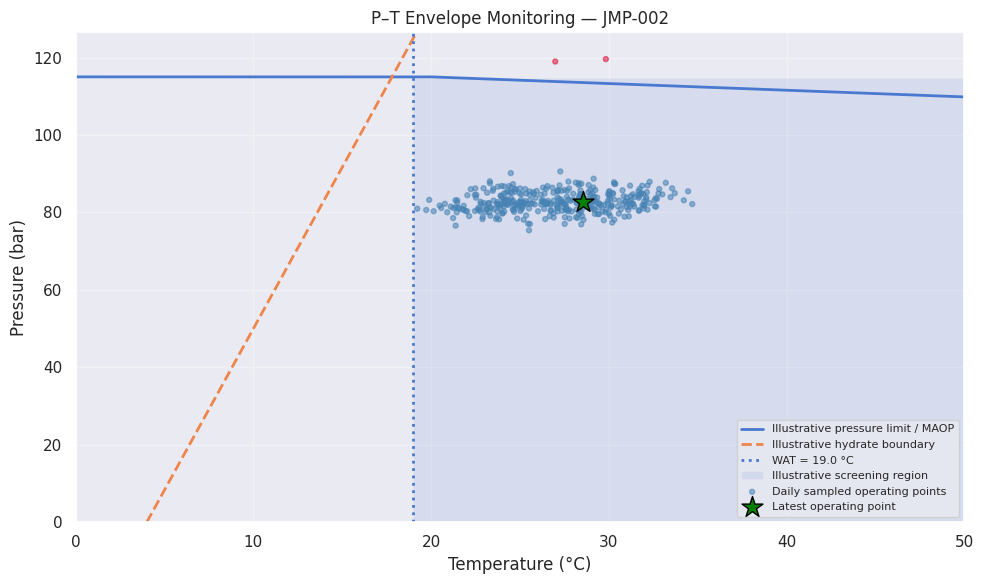

In [ ]:
def plot_pt_envelope(asset: SubseaAsset, data: pd.DataFrame):
    fig, ax = plt.subplots(figsize=(10, 6))

    temp_axis = np.linspace(0, 50, 300)
    pressure_axis = np.linspace(0, asset.maop_bar * 1.10, 300)

    # Pressure limit curve as a function of temperature.
    p_limit = asset.pressure_limit_bar(temp_axis)
    ax.plot(temp_axis, p_limit, linewidth=2, label="Illustrative pressure limit / MAOP")

    # Hydrate boundary plotted as temperature versus pressure.
    hydrate_temp = asset.hydrate_boundary_temp_c(pressure_axis)
    ax.plot(hydrate_temp, pressure_axis, linestyle="--", linewidth=2, label="Illustrative hydrate boundary")
    ax.axvline(asset.wat_c, linestyle=":", linewidth=2, label=f"WAT = {asset.wat_c:.1f} °C")

    # Approximate safe screening region: above WAT and hydrate boundary, below pressure limit.
    safe_temp = np.maximum(asset.wat_c, asset.hydrate_boundary_temp_c(pressure_axis))
    valid = pressure_axis <= asset.maop_bar
    ax.fill_betweenx(
        pressure_axis[valid],
        safe_temp[valid],
        50,
        alpha=0.12,
        label="Illustrative screening region"
    )

    sample = data.iloc[::24]
    colors = np.where(sample["envelope_exceedance"], "crimson", "steelblue")
    ax.scatter(sample["temperature_c"], sample["pressure_bar"], s=13, c=colors,
               alpha=0.55, label="Daily sampled operating points")

    current_color = "crimson" if bool(data.iloc[-1]["envelope_exceedance"]) else "green"
    ax.scatter(
        data.iloc[-1]["temperature_c"], data.iloc[-1]["pressure_bar"],
        marker="*", s=250, c=current_color, edgecolor="black",
        label="Latest operating point", zorder=5
    )

    ax.set_xlim(0, 50)
    ax.set_ylim(0, asset.maop_bar * 1.10)
    ax.set_xlabel("Temperature (°C)")
    ax.set_ylabel("Pressure (bar)")
    ax.set_title(f"P–T Envelope Monitoring — {asset.asset_id}")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best", fontsize=8)
    plt.tight_layout()
    plt.show()


plot_pt_envelope(selected_asset, asset_data)

8. Plot 2 — Corrosion trend and remaining-life projection
The upper chart displays monthly mean corrosion-rate estimates. The lower chart displays measured/simulated wall thickness and the minimum allowable wall threshold. The right-side text reports the latest linear remaining-life estimate.

For field use, wall-thickness trends should be based on qualified inspection measurements and corrosion rates should consider measurement uncertainty and localized damage.



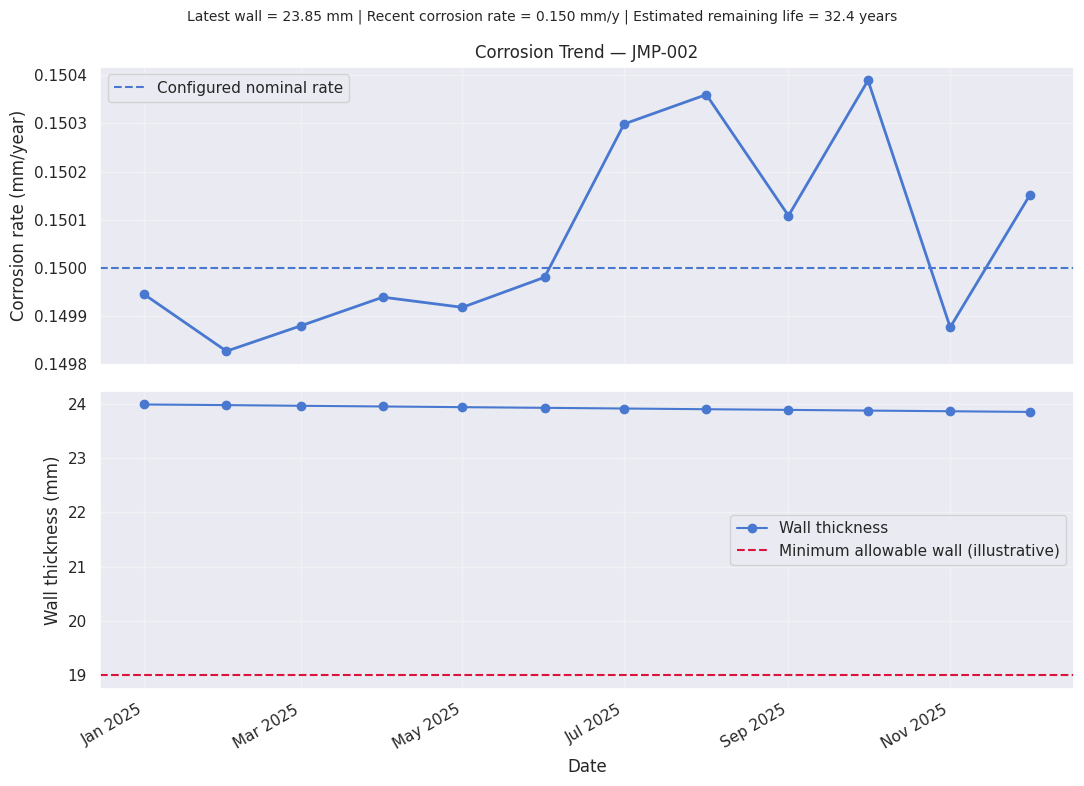

In [ ]:
def plot_corrosion(asset: SubseaAsset, data: pd.DataFrame):
    g = data.set_index("timestamp").sort_index()
    monthly_rate = g["corrosion_rate_mm_y"].resample("MS").mean()
    monthly_wall = g["wall_thickness_mm"].resample("MS").last()
    recent_rate = g["corrosion_rate_mm_y"].tail(24 * 30).mean()
    current_wall = g["wall_thickness_mm"].iloc[-1]
    remaining_life = asset.remaining_life_years(current_wall, recent_rate)

    fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

    axes[0].plot(monthly_rate.index, monthly_rate.values, marker="o", linewidth=2)
    axes[0].axhline(asset.nominal_corrosion_mm_y, linestyle="--",
                    label="Configured nominal rate")
    axes[0].set_ylabel("Corrosion rate (mm/year)")
    axes[0].set_title(f"Corrosion Trend — {asset.asset_id}")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    axes[1].plot(monthly_wall.index, monthly_wall.values, marker="o",
                 label="Wall thickness")
    axes[1].axhline(asset.minimum_wall_mm, color="crimson", linestyle="--",
                    label="Minimum allowable wall (illustrative)")
    axes[1].set_ylabel("Wall thickness (mm)")
    axes[1].set_xlabel("Date")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

    fig.suptitle(
        f"Latest wall = {current_wall:.2f} mm | "
        f"Recent corrosion rate = {recent_rate:.3f} mm/y | "
        f"Estimated remaining life = {remaining_life:.1f} years",
        fontsize=10
    )
    axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()


plot_corrosion(selected_asset, asset_data)

9. Plot 3 — Fatigue damage accumulation tracker
Miner’s rule estimates cumulative fatigue damage:

[ D = \sum_i \frac{n_i}{N_i} ]

where (n_i) is the number of applied cycles at stress range (i), and (N_i) is the estimated cycles to failure at that stress range. In this simplified synthetic example, each hourly stress-range sample is treated as one equivalent cycle.

The chart includes example watch and critical thresholds of 0.10 and 0.20. These are dashboard demonstration thresholds, not universal acceptance criteria. A validated fatigue assessment normally requires appropriate cycle counting (for example, rainflow), stress concentration/fatigue factors, applicable S–N curves, environmental corrections, and design fatigue factors.

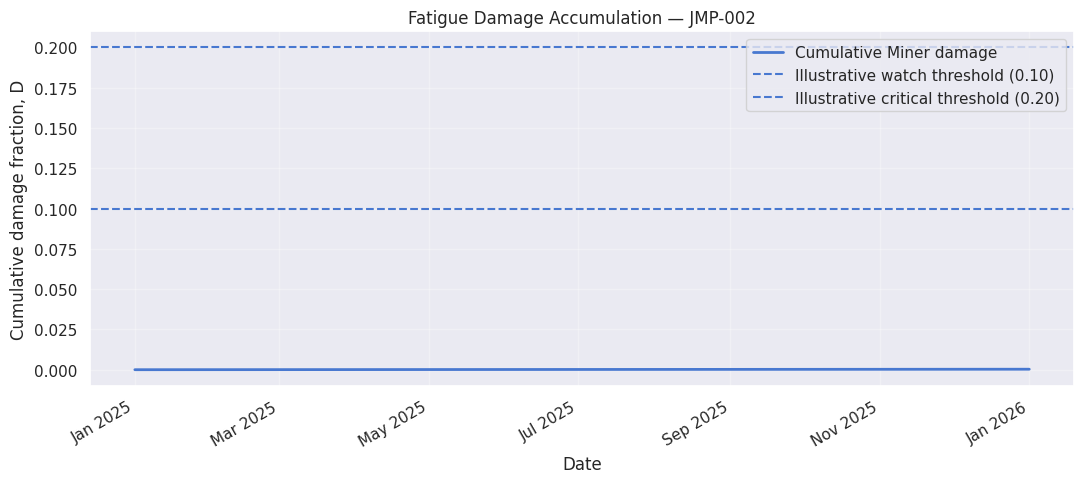

In [ ]:
def plot_fatigue(asset: SubseaAsset, data: pd.DataFrame):
    g = data.sort_values("timestamp")
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(g["timestamp"], g["cumulative_fatigue_damage"],
            linewidth=2, label="Cumulative Miner damage")
    ax.axhline(0.10, linestyle="--", label="Illustrative watch threshold (0.10)")
    ax.axhline(0.20, linestyle="--", label="Illustrative critical threshold (0.20)")
    ax.set_title(f"Fatigue Damage Accumulation — {asset.asset_id}")
    ax.set_xlabel("Date")
    ax.set_ylabel("Cumulative damage fraction, D")
    ax.grid(True, alpha=0.3)
    ax.legend()
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()


plot_fatigue(selected_asset, asset_data)

10. Plot 4 — Automated alert timeline and current alert table
Alerts are generated from explicit rules. The timeline displays hours where any envelope exceedance occurred. The table lists the most recent non-normal records, including the reason for the alert.

A dashboard alert is a screening signal that should trigger verification and review; it should not directly control subsea equipment without a separately engineered, validated, and safety-assessed control system.

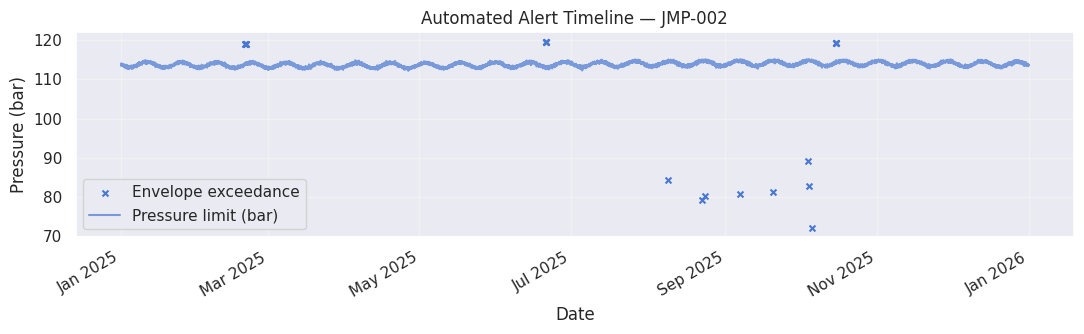

,timestamp,asset_id,alert_level,pressure_bar,temperature_c,pressure_limit_bar,wall_thickness_mm,remaining_life_years,cumulative_fatigue_damage,alert_reason
27480,2025-02-20 00:00:00,JMP-002,WARNING,118.962058,26.983739,113.795305,23.979094,33.214117,0.000042,Pressure above limit
27481,2025-02-20 01:00:00,JMP-002,WARNING,118.962058,24.588637,114.208460,23.979078,33.212409,0.000042,Pressure above limit
27482,2025-02-20 02:00:00,JMP-002,WARNING,118.962058,27.545395,113.698419,23.979063,33.212953,0.000042,Pressure above limit
27483,2025-02-20 03:00:00,JMP-002,WARNING,118.962058,27.514363,113.703772,23.979049,33.215255,0.000042,Pressure above limit
27484,2025-02-20 04:00:00,JMP-002,WARNING,118.962058,26.429392,113.890930,23.979033,33.213040,0.000042,Pressure above limit
30380,2025-06-20 20:00:00,JMP-002,WARNING,119.589643,32.404635,112.860200,23.929502,32.844583,0.000142,Pressure above limit
30381,2025-06-20 21:00:00,JMP-002,WARNING,119.589643,31.323298,113.046731,23.929487,32.844691,0.000142,Pressure above limit
30382,2025-06-20 22:00:00,JMP-002,WARNING,119.589643,29.509216,113.359660,23.929472,32.846147,0.000142,Pressure above limit
30383,2025-06-20 23:00:00,JMP-002,WARNING,119.589643,33.420399,112.684981,23.929457,32.848721,0.000143,Pressure above limit
30384,2025-06-21 00:00:00,JMP-002,WARNING,119.589643,29.828417,113.304598,23.929442,32.849028,0.000143,Pressure above limit


In [ ]:
def explain_alert(row, asset: SubseaAsset):
    reasons = []
    if row["pressure_exceedance"]:
        reasons.append("Pressure above limit")
    if row["hydrate_risk"]:
        reasons.append("Temperature below hydrate boundary")
    if row["wat_risk"]:
        reasons.append("Temperature below WAT")
    if row["wall_thickness_mm"] <= asset.minimum_wall_mm:
        reasons.append("Wall thickness at/below minimum")
    if row["cumulative_fatigue_damage"] >= 0.20:
        reasons.append("Fatigue damage at/above critical threshold")
    if row["remaining_life_years"] <= 5:
        reasons.append("Estimated remaining corrosion life ≤ 5 years")
    return "; ".join(reasons) if reasons else "No rule triggered"


def plot_alert_timeline(asset: SubseaAsset, data: pd.DataFrame):
    g = data.sort_values("timestamp")
    fig, ax = plt.subplots(figsize=(11, 3.5))
    alert_rows = g[g["envelope_exceedance"]]
    ax.scatter(alert_rows["timestamp"], alert_rows["pressure_bar"],
               s=18, marker="x", label="Envelope exceedance")
    ax.plot(g["timestamp"], g["pressure_limit_bar"], alpha=0.7,
            label="Pressure limit (bar)")
    ax.set_title(f"Automated Alert Timeline — {asset.asset_id}")
    ax.set_xlabel("Date")
    ax.set_ylabel("Pressure (bar)")
    ax.grid(True, alpha=0.3)
    ax.legend()
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()


plot_alert_timeline(selected_asset, asset_data)

alert_table = asset_data.loc[asset_data["alert_level"] != "NORMAL"].copy()
alert_table["alert_reason"] = alert_table.apply(
    lambda row: explain_alert(row, selected_asset), axis=1
)
display(alert_table[[
    "timestamp", "asset_id", "alert_level", "pressure_bar", "temperature_c",
    "pressure_limit_bar", "wall_thickness_mm", "remaining_life_years",
    "cumulative_fatigue_damage", "alert_reason"
]].tail(25))

11. Fleet overview plots
These plots compare all eight assets so the integrity engineer can identify assets requiring attention. The estimates should be interpreted alongside inspection history, design documentation, and operating context.

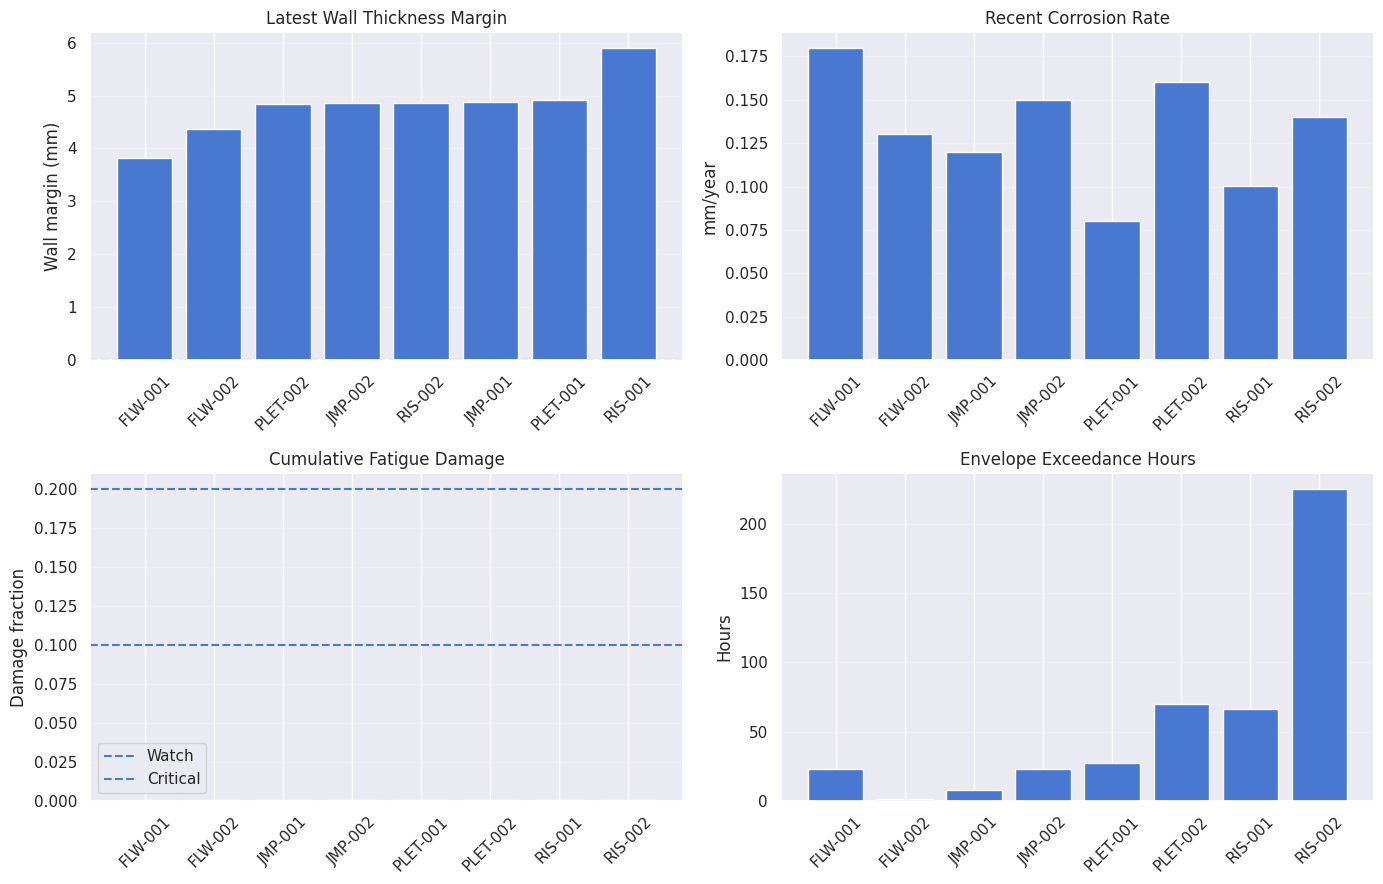

,asset_id,asset_type,latest_pressure_bar,latest_temperature_c,latest_wall_thickness_mm,minimum_wall_mm,wall_margin_mm,recent_corrosion_rate_mm_y,estimated_remaining_life_y,cumulative_fatigue_damage,envelope_exceedance_hours,critical_hours,latest_alert
0,FLW-001,Flowline,71.883,29.518,19.82,16.0,3.82,0.18,21.229,0.0,23,0,NORMAL
1,FLW-002,Flowline,73.884,27.041,21.87,17.5,4.37,0.13,33.580,0.0,1,0,NORMAL
2,JMP-001,Production Jumper,84.156,28.062,24.88,20.0,4.88,0.12,40.673,0.0,8,0,NORMAL
3,JMP-002,Production Jumper,82.584,28.533,23.85,19.0,4.85,0.15,32.395,0.0,23,0,NORMAL
4,PLET-001,PLET,87.588,28.905,27.92,23.0,4.92,0.08,61.533,0.0,27,0,NORMAL
5,PLET-002,PLET,76.055,27.721,25.84,21.0,4.84,0.16,30.188,0.0,70,0,NORMAL
6,RIS-001,Production Riser,97.935,30.095,31.90,26.0,5.90,0.10,58.975,0.0,66,0,NORMAL
7,RIS-002,Production Riser,97.123,29.825,29.86,25.0,4.86,0.14,34.687,0.0,225,0,NORMAL


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Latest wall thickness margin
summary_sorted = fleet_summary.sort_values("wall_margin_mm")
axes[0, 0].bar(summary_sorted["asset_id"], summary_sorted["wall_margin_mm"])
axes[0, 0].axhline(0, linestyle="--")
axes[0, 0].set_title("Latest Wall Thickness Margin")
axes[0, 0].set_ylabel("Wall margin (mm)")
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].grid(axis="y", alpha=0.25)

# Corrosion rate
axes[0, 1].bar(fleet_summary["asset_id"], fleet_summary["recent_corrosion_rate_mm_y"])
axes[0, 1].set_title("Recent Corrosion Rate")
axes[0, 1].set_ylabel("mm/year")
axes[0, 1].tick_params(axis="x", rotation=45)
axes[0, 1].grid(axis="y", alpha=0.25)

# Fatigue damage
axes[1, 0].bar(fleet_summary["asset_id"], fleet_summary["cumulative_fatigue_damage"])
axes[1, 0].axhline(0.10, linestyle="--", label="Watch")
axes[1, 0].axhline(0.20, linestyle="--", label="Critical")
axes[1, 0].set_title("Cumulative Fatigue Damage")
axes[1, 0].set_ylabel("Damage fraction")
axes[1, 0].tick_params(axis="x", rotation=45)
axes[1, 0].legend()
axes[1, 0].grid(axis="y", alpha=0.25)

# Envelope exceedance hours
axes[1, 1].bar(fleet_summary["asset_id"], fleet_summary["envelope_exceedance_hours"])
axes[1, 1].set_title("Envelope Exceedance Hours")
axes[1, 1].set_ylabel("Hours")
axes[1, 1].tick_params(axis="x", rotation=45)
axes[1, 1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

display(fleet_summary.round(3))